## Complete Data Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Original dataset

In [2]:
data = pd.read_csv("CivicDataset.csv") ## Original Dataset
data2 = pd.read_csv("complaints_hinglish.csv") ## Synthetic dataset

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   original_id              16000 non-null  object
 1   Complain_date            16000 non-null  object
 2   complaint_title          16000 non-null  object
 3   text_en                  16000 non-null  object
 4   location_address         8836 non-null   object
 5   category_primary         15561 non-null  object
 6   category_secondary       16000 non-null  object
 7   resolution_status        16000 non-null  object
 8   comment_count            16000 non-null  int64 
 9   Hindi                    16000 non-null  object
 10  Hinglish                 16000 non-null  object
 11  severity                 16000 non-null  object
 12  severity_score           16000 non-null  int64 
 13  high_keywords_matched    2816 non-null   object
 14  medium_keywords_matched  5328 non-null

In [4]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Sy_No               15000 non-null  int64 
 1   Complaint_Title     15000 non-null  object
 2   Text_en             15000 non-null  object
 3   Text_hi             15000 non-null  object
 4   Text_hinglish       15000 non-null  object
 5   primary_category    15000 non-null  object
 6   secondary_category  15000 non-null  object
 7   Severity            15000 non-null  object
 8   Model_Name          15000 non-null  object
dtypes: int64(1), object(8)
memory usage: 1.0+ MB


In [18]:
# Complete Data Visualization Code with Enhanced Word Clouds
# All figures saved in 'dataset_visuals' folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
import re
import nltk
from nltk.corpus import stopwords
import warnings
import os
from pathlib import Path

# Download stopwords if not available
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('stopwords')
    nltk.download('punkt')

warnings.filterwarnings('ignore')

# Create folder for saving visualizations
output_folder = Path("dataset_visuals")
output_folder.mkdir(exist_ok=True)

# Set style and color palette
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ============================================================================
# ENHANCED STOPWORDS FOR HINDI AND HINGLISH
# ============================================================================

print("="*80)
print("LOADING ENHANCED STOPWORDS FOR HINDI AND HINGLISH")
print("="*80)

# English stopwords
english_stopwords = set(stopwords.words('english'))

# Enhanced Hindi stopwords (expanded)
hindi_stopwords = {
    # Basic pronouns
    'है','हैं','था','थी','थे','हो','होगा','होगी','होंगे','हुआ','हुई','हुए',
    'का','की','के','को','में','पर','से','तक','लिए','द्वारा','कर','करके',
    'और','या','तथा','लेकिन','किन्तु','परंतु','अथवा','अर्थात','यानी','मतलब',
    'यह','ये','वह','वे','इस','उस','इन','उन','इसे','उसे','इन्हें','उन्हें',
    'मैं','हम','आप','तुम','तू','वो','जो','जिस','जिसे','जिसका','जिसकी','जिसके',
    'जिन','जिन्हें','जिनका','जिनकी','जिनके','मुझे','हमें','तुम्हें','आपको',
    'एक','दो','तीन','चार','पांच','छह','सात','आठ','नौ','दस','सौ','हजार',
    'न','ना','नहीं','मत','नही','नहि','नाही','मत्कर',
    'भी','ही','तो','तोही','हीही','भीतो','तोभी',
    'यदि','अगर','जब','तब','कब','जहाँ','वहाँ','जहां','वहां',
    'क्यों','कैसे','क्या','कौन','किस','किसका','किसकी','किसके',
    'किसी','किसीभी','कुछ','सभी','सब','हर','प्रत्येक','कोई','कोइ',
    'बहुत','अधिक','कम','काफी','लगभग','थोड़ा','थोड़ी','थोड़े','ज्यादा','ज़्यादा',
    'बाद','पहले','फिर','पुनः','दोबारा','फिरसे','फिरस','दुबारा',
    'अभी','अब','तभी','सदा','हमेशा','अक्सर','प्रायः','कभी','कभीकभी',
    'आज','कल','परसों','तरसों','आजकल','कलकल',
    'ऊपर','नीचे','आगे','पीछे','पास','दूर','नजदीक','निकट',
    'अंदर','बाहर','बीच','सामने','पीछे','बगल','आसपास',
    'कर','किया','किये','कीजिए','करना','करते','करती','करता','करेंगे','करूंगा',
    'करें','करो','करु','करू','करे','करेंगी','करोगे','करता','करती',
    'होना','होते','होती','होता','होंगे','होंगी','हुआ','हुई','हुए',
    'गया','गई','गए','जाता','जाती','जाते','जाओ','जाए','जाये',
    'रहा','रही','रहे','रहें','रहूंगा','रहेंगे',
    'बना','बनी','बने','बनाओ','बनाया','बनाई','बनाए',
    'लिया','लिए','ली','देना','दिया','दिए','दी','दो','दे',
    'रूप','तरह','प्रकार','संबंधित','सम्बंधित','अनुसार',
    'मात्र','सिर्फ','केवल','सिर्फ़','केवल','भर','मात्रा',
    'वाले','वाली','वाला','वालों','वाली','वाला',
    'सकता','सकती','सकते','सकूं','सके','सकी','सकूंगा',
    'चाहिए','चाहिये','चाहिये','चाही','चाहिये',
    'क्योंकि','इसलिए','अतः','अतएव','चूंकि','क्यूंकि',
    'दूसरा','दूसरी','दूसरे','दूसरो','दूसरों',
    'पहला','पहली','पहले','पहलो','पहलों',
    'इत्यादि','आदि','वगैरह','इत्यादी','वगेरह',
    'प्रति','बिना','साथ','सहित','समेत','सहित',
    'जनाब','श्री','श्रीमती','श्रीमान','श्रीमति',
    'लगता','लगती','लगते','लगा','लगी','लगे',
    'रखना','रखा','रखी','रखे','रखो','रखू',
    'चल','चलो','चलिए','चलें','चले','चलो',
    'उपरांत','पूर्व','पश्चात','उपरान्त','पश्चात',
    'वर्तमान','भविष्य','भूत','वर्तमान','भविष्य',
    'तुम्हारा','तुम्हारी','तुम्हारे','तुम्हारो',
    'हमारा','हमारी','हमारे','हमारो',
    'मेरा','मेरी','मेरे','मेरो',
    'अपना','अपनी','अपने','अपनो','अपनों',
    'यही','वही','इसी','उसी','यहीं','वहीं',
    'जैसा','जैसी','जैसे','जैसेकि',
    'वैसा','वैसी','वैसे','वैसाही',
    'पूरा','पूरी','पूरे','पुरा','पुरी','पुरे',
    'आधा','आधी','आधे','आधा',
    'लगातार','निरंतर','निरन्तर','लगातार',
    'जरूर','अवश्य','जरुर','जरूरी','अवश्य',
    'हर','हरएक','हरेक','प्रत्येक',
    'कभी','कभीकभी','कभी-कभी','कभिन',
    'केअंदर','केबाहर','केबीच','केसाथ',
    'जोकि','जोकी','जोके','जिसने','जिसने',
    'जिन्होंने','जिन्होने','जिसको','जिनको',
    'उसके','उनके','इसके','इनके',
    'उसपर','उनपर','इसपर','इनपर',
    'वगैरह','वगेरह','इत्यादि','आदि',
}

# Enhanced Hinglish stopwords (expanded)
hinglish_stopwords = {
    # Basic Hinglish
    'hai','hain','tha','thi','the','ho','hoga','hogi','honge','hua','hui','hue',
    'ka','ki','ke','ko','mein','main','me','par','pe','se','tak','liye','liyee','liyeh','dwara',
    'aur','ya','tatha','lekin','kintu','parantu','magar','but','or','and',
    'ye','yeh','yah','wo','woh','vo','is','us','in','un','ise','use','inhain','unhain',
    'mai','main','hum','ham','aap','tum','tu','vo','jo','jis','jise','jiska','jiski','jiske',
    'jin','jinhe','jinhein','jinhe','jinka','jinki','jinke',
    'mujhe','hume','hame','tumhe','aapko','isko','usko','unko','inko','unhain',
    'ek','do','teen','char','paanch','che','saat','ath','nau','das','so','hazar',
    'na','nahi','nahin','mat','nahi','nahin','naheen','matt',
    'bhi','hi','to','toh','tohi','to bhi','hi toh',
    'agar','yadi','jab','tab','kab','jaha','waha','jahaan','wahaan','jahape','wahape',
    'kya','kyaa','kaun','kaise','kyun','kyon','kaisa','kaisi','kaise',
    'kisi','kisiko','kiska','kiski','kiske','kuch','kuchh',
    'sab','sabhi','har','pratyek','koi','koee','koyi',
    'bahut','zyada','jada','adhik','kam','kaafi','lagbhag','thora','thori','thore','jayada','jyaada',
    'baad','pehle','fir','phir','dobara','firse','duabara','phirse',
    'abhi','ab','tabhi','sada','hamesha','aksar','kabhi','kabhi kabhi',
    'aaj','kal','parson','ajkal','kal','parson',
    'upar','neeche','aage','peeche','paas','door','nazdeek','nazdik',
    'andar','bahar','beech','samne','pichhe','bagal','aaspaas',
    'kar','karo','karna','kiya','kiye','karne','karta','karti','karte','karenge','karunga',
    'kare','karen','karoge','karta','karti','karte','karu','karega','karegi',
    'hona','hote','hoti','hota','honge','hongi','hota','hoti','hote',
    'gaya','gayi','gaye','jata','jati','jate','jao','jaaye','jaye',
    'raha','rahi','rahe','rahenge','raha','rahi','rahe',
    'bana','bani','bane','banao','banaya','banai','banaye','banayen',
    'liya','liye','li','dena','diya','diye','di','do','de','lena','lena',
    'roop','tarah','prakar','sambandhit','anusar',
    'matra','sirf','keval','bhar','sirf','keval',
    'wale','wali','wala','walo','walon',
    'sakta','sakti','sakte','sakoon','sake','saki','sakunga',
    'chahiye','chahiyeh','chahi','chahie','chahiyee',
    'kyunki','isliye','atah','atev','chunki','kyunki',
    'dusra','dusri','dusre','dusro','dusron',
    'pehla','pehli','pehle','pehlo','pehlon',
    'etc','wagairah','vagera','wagera','wagerah','ityadi','adi',
    'prati','bina','saath','sath','sahit','sahit',
    'janab','shri','shrimati','shriman',
    'lagta','lagti','lagte','laga','lagi','lage',
    'rakhna','rakha','rakhi','rakhe','rakho','rakhu',
    'chalo','chaliye','chale','chaliye','chalen',
    'tumhara','tumhari','tumhare','tumharo',
    'hamara','hamari','hamare','hamaro',
    'mera','meri','mere','mero',
    'apna','apni','apne','apno','apnon',
    'yahi','wahi','isi','usi','yahin','wahin',
    'jaise','jaisa','jaisi','jaiseki',
    'waise','waisa','waisi','waisahi',
    'poora','poori','poore','pura','puri','pure',
    'aadha','aadhi','aadhe','aadha',
    'lagatar','nirantar','lagaatar',
    'zarur','jarur','avashya','jaroor','zaroor','zaruri',
    'har','harek','pratyek',
    'kabhi','kabhi kabhi','kabhi-kabhi','kabhi kabhi',
    'andar','bahar','beech','saath','sath',
    'joki','jiske','jisne','jinhone','jisko','jinko',
    'uske','unke','iske','inke',
    'uspar','unpar','ispar','inpar',
    # English words commonly used in Hinglish
    'please','plz','pls','okay','ok','haan','han','ji','sir','madam',
    'bhai','bhaiya','didi','are','arre','abe','hello','hi','hey',
    'good','bad','very','much','many','more','less','few','some',
    'all','every','any','can','could','would','should','will','shall',
    'am','is','are','was','were','be','been','being','do','does','did',
    'have','has','had','from','for','of','on','at','by','with','without',
    'into','onto','about','during','before','after','because','therefore',
    'then','than','that','this','these','those','it','its','their',
    'our','your','my','mine','yours','ours','him','her','them',
    'such','same','another','already','still','ever','never','always',
    'sometimes','often','maybe','perhaps','also','too','as','so',
    'just','only','well','now','then','there','here','where',
    'like','unlike','along','while','among','between','across',
    'however','although','though','whereas','meanwhile','finally',
    'first','second','third','next','last','finally','meanwhile',
    'further','furthermore','moreover','accordingly','consequently',
    'namely','specifically','generally','usually','eventually',
    'rather','quite','almost','mostly','sometimes','hardly',
    'anyway','anyways','whatever','whichever','whoever',
    'even','evenif','eventhough','again','againandagain',
    'ago','before','afterwards','afterward','meanwhile',
    'ago','before','afterwards','afterward','meanwhile',
    # Additional common Hinglish words
    'accha','acha','theek','thik','chalo','chale','chaliye',
    'kya','kaise','kyun','kab','kaha','kaun','kiska','kiski',
    'nahi','na','mat','haan','han','yes','no','sahi','galat',
    'bas','bass','yaar','dost','friend','buddy','man','guy',
    'dekho','dekh','sun','suno','samajh','samajho','jao','jaiye',
    'ao','aao','aaiye','aaye','aayen','chalo','chaliye',
    'bat','batao','bata','bolo','bol','karo','kar',
    'acha','sahi','galat','achha','thik','ok','okay','alright',
    'ready','set','go','start','stop','wait','ruk','ruko',
    'koi','koee','kuch','kuchh','thoda','thodi','thode','zyada',
    'kam','bahut','kaafi','pura','poora','sara','saara','sab',
    'mil','milo','milte','milen','aapas','mein','main','hum',
    'tum','vo','ye','yah','wo','woh','yeh','voh',
}

print(f"✅ English stopwords: {len(english_stopwords)}")
print(f"✅ Hindi stopwords: {len(hindi_stopwords)}")
print(f"✅ Hinglish stopwords: {len(hinglish_stopwords)}")

# ============================================================================
# CLEANING FUNCTIONS WITH ENHANCED STOPWORDS
# ============================================================================

def clean_english(text):
    """Clean English text by removing stopwords and special characters"""
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [word for word in text.split() if word not in english_stopwords and len(word) > 1]
    return " ".join(words)

def clean_hindi(text):
    """Clean Hindi text by removing stopwords"""
    text = str(text)
    words = [word for word in text.split() if word not in hindi_stopwords and len(word) > 1]
    return " ".join(words)

def clean_hinglish(text):
    """Clean Hinglish text by removing stopwords"""
    text = str(text).lower()
    words = [word for word in text.split() if word not in hinglish_stopwords and len(word) > 1]
    return " ".join(words)

# ============================================================================
# LOAD DATASETS
# ============================================================================

print("\n" + "="*80)
print("LOADING DATASETS")
print("="*80)

data = pd.read_csv("CivicDataset.csv")  # Original Dataset
data2 = pd.read_csv("complaints_hinglish.csv")  # Synthetic dataset

print(f"✅ Original dataset: {len(data)} rows")
print(f"✅ Synthetic dataset: {len(data2)} rows")

# ============================================================================
# PREPARE TEXT FOR WORD CLOUDS (Enhanced with all columns)
# ============================================================================

print("\n" + "="*80)
print("PREPARING TEXT FOR WORD CLOUDS")
print("="*80)

# For original dataset
english_text_original = " ".join(data['text_en'].dropna().astype(str))
hindi_text_original = " ".join(data['Hindi'].dropna().astype(str))
hinglish_text_original = " ".join(data['Hinglish'].dropna().astype(str))

# For synthetic dataset - combine multiple columns
english_text_synthetic = " ".join((data2["Complaint_Title"] + " " + data2["Text_en"]).astype(str))
hindi_text_synthetic = " ".join(data2["Text_hi"].astype(str))
hinglish_text_synthetic = " ".join(data2["Text_hinglish"].astype(str))

# Combine original and synthetic for richer word clouds
english_text = english_text_original + " " + english_text_synthetic
hindi_text = hindi_text_original + " " + hindi_text_synthetic
hinglish_text = hinglish_text_original + " " + hinglish_text_synthetic

print(f"✅ English text length: {len(english_text)} characters")
print(f"✅ Hindi text length: {len(hindi_text)} characters")
print(f"✅ Hinglish text length: {len(hinglish_text)} characters")

# Clean texts
english_text = clean_english(english_text)
hindi_text = clean_hindi(hindi_text)
hinglish_text = clean_hinglish(hinglish_text)

print(f"✅ Cleaned English text: {len(english_text)} characters")
print(f"✅ Cleaned Hindi text: {len(hindi_text)} characters")
print(f"✅ Cleaned Hinglish text: {len(hinglish_text)} characters")

# ============================================================================
# ENHANCED WORD CLOUD GENERATION WITH PROPER FONT
# ============================================================================

def get_font_path():
    """Get appropriate font path for Hindi/Devanagari text"""
    font_paths = [
        # Windows
        r"C:\Windows\Fonts\Nirmala.ttc",
        r"C:\Windows\Fonts\mangal.ttf",
        r"C:\Windows\Fonts\Arial Unicode.ttf",
        r"C:\Windows\Fonts\Kokila.ttf",
        # macOS
        "/System/Library/Fonts/Supplemental/Arial Unicode.ttf",
        "/System/Library/Fonts/Supplemental/AppleGothic.ttf",
        # Linux
        "/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
        "/usr/share/fonts/truetype/ttf-indic-fonts-core/lohit-hindi.ttf",
    ]
    
    for path in font_paths:
        if os.path.exists(path):
            return path
    return None

font_path = get_font_path()
if font_path:
    print(f"✅ Using font: {font_path}")
else:
    print("⚠️ No Devanagari font found, using default font")

# Combined word cloud (Figure 7)
print("\n📊 Creating combined word clouds (Figure 7)...")

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# English Word Cloud
wc_en = WordCloud(
    width=800, height=600,
    background_color='white',
    colormap='viridis',
    max_words=200,
    min_font_size=8,
    max_font_size=80,
    contour_width=1,
    contour_color='steelblue',
    random_state=42,
    collocations=False
).generate(english_text[:500000])  # Limit text for performance

axes[0].imshow(wc_en, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('English Word Cloud', fontsize=18, fontweight='bold', pad=20)

# Hindi Word Cloud
try:
    wc_hi = WordCloud(
        width=800, height=600,
        background_color='white',
        colormap='plasma',
        max_words=200,
        min_font_size=8,
        max_font_size=80,
        contour_width=1,
        contour_color='darkred',
        random_state=42,
        collocations=False,
        font_path=font_path if font_path else None
    ).generate(hindi_text[:500000])
    
    axes[1].imshow(wc_hi, interpolation='bilinear')
except Exception as e:
    print(f"⚠️ Hindi word cloud error: {e}")
    # Fallback: show bar chart
    from collections import Counter
    words = re.findall(r'[\u0900-\u097F]+', hindi_text)
    word_freq = Counter(words).most_common(30)
    if word_freq:
        top_words, top_freq = zip(*word_freq)
        axes[1].barh(top_words, top_freq, color='plasma')
        axes[1].set_title('Hindi: Most Common Words', fontsize=14, fontweight='bold')
        axes[1].tick_params(axis='y', labelsize=10)
    else:
        axes[1].text(0.5, 0.5, 'Hindi text not available', ha='center', va='center', fontsize=14)
        axes[1].axis('off')

axes[1].axis('off')
axes[1].set_title('Hindi Word Cloud', fontsize=18, fontweight='bold', pad=20)

# Hinglish Word Cloud
wc_hinglish = WordCloud(
    width=800, height=600,
    background_color='white',
    colormap='inferno',
    max_words=200,
    min_font_size=8,
    max_font_size=80,
    contour_width=1,
    contour_color='darkorange',
    random_state=42,
    collocations=False
).generate(hinglish_text[:500000])

axes[2].imshow(wc_hinglish, interpolation='bilinear')
axes[2].axis('off')
axes[2].set_title('Hinglish Word Cloud', fontsize=18, fontweight='bold', pad=20)

plt.suptitle('FIGURE 7: Word Clouds for English, Hindi, and Hinglish', 
             fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_folder / 'figure7_wordclouds.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: figure7_wordclouds.png")

# ============================================================================
# SEPARATE WORD CLOUDS WITH ENHANCED SETTINGS
# ============================================================================

print("\n📊 Creating separate enhanced word clouds...")

# English Word Cloud - Separate
fig, ax = plt.subplots(figsize=(14, 10))
wc_en = WordCloud(
    width=1200, height=800,
    background_color='white',
    colormap='viridis',
    max_words=300,
    min_font_size=10,
    max_font_size=120,
    contour_width=2,
    contour_color='steelblue',
    random_state=42,
    collocations=False
).generate(english_text)
ax.imshow(wc_en, interpolation='bilinear')
ax.axis('off')
ax.set_title('English Word Cloud', fontsize=24, fontweight='bold', pad=30)
plt.tight_layout()
plt.savefig(output_folder / 'wordcloud_english.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: wordcloud_english.png")

# Hindi Word Cloud - Separate with font
fig, ax = plt.subplots(figsize=(14, 10))
try:
    wc_hi = WordCloud(
        width=1200, height=800,
        background_color='white',
        colormap='plasma',
        max_words=300,
        min_font_size=10,
        max_font_size=120,
        contour_width=2,
        contour_color='darkred',
        random_state=42,
        collocations=False,
        font_path=font_path if font_path else None
    ).generate(hindi_text)
    ax.imshow(wc_hi, interpolation='bilinear')
except Exception as e:
    print(f"⚠️ Error generating Hindi word cloud: {e}")
    # Fallback visualization
    from collections import Counter
    words = re.findall(r'[\u0900-\u097F]+', hindi_text)
    word_freq = Counter(words).most_common(40)
    if word_freq:
        top_words, top_freq = zip(*word_freq)
        ax.barh(top_words, top_freq, color='plasma')
        ax.set_xlabel('Frequency', fontsize=14)
        ax.tick_params(axis='y', labelsize=12)
    else:
        ax.text(0.5, 0.5, 'No Hindi text available', ha='center', va='center', fontsize=18)
        ax.axis('off')

ax.axis('off')
ax.set_title('Hindi Word Cloud', fontsize=24, fontweight='bold', pad=30)
plt.tight_layout()
plt.savefig(output_folder / 'wordcloud_hindi.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: wordcloud_hindi.png")

# Hinglish Word Cloud - Separate
fig, ax = plt.subplots(figsize=(14, 10))
wc_hinglish = WordCloud(
    width=1200, height=800,
    background_color='white',
    colormap='inferno',
    max_words=300,
    min_font_size=10,
    max_font_size=120,
    contour_width=2,
    contour_color='darkorange',
    random_state=42,
    collocations=False
).generate(hinglish_text)
ax.imshow(wc_hinglish, interpolation='bilinear')
ax.axis('off')
ax.set_title('Hinglish Word Cloud', fontsize=24, fontweight='bold', pad=30)
plt.tight_layout()
plt.savefig(output_folder / 'wordcloud_hinglish.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: wordcloud_hinglish.png")

# ============================================================================
# COMPLETE VISUALIZATIONS FOR ALL TABLES AND FIGURES
# ============================================================================

print("\n" + "="*80)
print("GENERATING ALL VISUALIZATIONS")
print("="*80)

# Table 4: Language Distribution in Original Dataset
print("\n📊 TABLE 4: Language Distribution in Original Dataset")
print("-"*40)

language_counts = {
    'English': len(data['text_en'].dropna()),
    'Hindi': len(data['Hindi'].dropna()),
    'Hinglish': len(data['Hinglish'].dropna())
}
lang_df = pd.DataFrame(list(language_counts.items()), columns=['Language', 'Samples'])
print(lang_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('tight')
ax.axis('off')
table_data = [['Language', 'Samples']] + [[k, v] for k, v in language_counts.items()]
table = ax.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.3, 0.3])
table.auto_set_font_size(False)
table.set_fontsize(14)
table.scale(1.2, 1.5)
for i in range(len(table_data)):
    for j in range(len(table_data[i])):
        if i == 0:
            table[(i, j)].set_facecolor('#4ECDC4')
            table[(i, j)].set_text_props(weight='bold', color='white')
        else:
            table[(i, j)].set_facecolor('#f5f5f5')
plt.title('TABLE 4: Language Distribution in Original Dataset', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(output_folder / 'table4_language_distribution.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: table4_language_distribution.png")

# Figure 3: Class Distribution
print("\n📊 FIGURE 3: Class Distribution of Original Dataset (Primary Categories)")
print("-"*40)

category_counts = data['category_primary'].value_counts()
top_categories = category_counts.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Bar Chart
ax1 = axes[0]
bars = ax1.barh(top_categories.index, top_categories.values, color=plt.cm.viridis(range(len(top_categories))))
ax1.set_xlabel('Number of Complaints', fontsize=12)
ax1.set_ylabel('Primary Category', fontsize=12)
ax1.set_title('Top 15 Primary Categories Distribution', fontsize=14, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

for i, (bar, val) in enumerate(zip(bars, top_categories.values)):
    ax1.text(val + 50, bar.get_y() + bar.get_height()/2, 
             f'{val:,}', va='center', ha='left', fontsize=10)

# Pie Chart
ax2 = axes[1]
top10_categories = category_counts.head(10)
other_count = category_counts.iloc[10:].sum()
pie_data = list(top10_categories.values) + [other_count]
pie_labels = list(top10_categories.index) + ['Others']
colors_pie = plt.cm.Set3(range(len(pie_data)))
wedges, texts, autotexts = ax2.pie(pie_data, labels=pie_labels, autopct='%1.1f%%',
                                    colors=colors_pie, startangle=90)
ax2.set_title('Category Distribution (Top 10 + Others)', fontsize=14, fontweight='bold')
plt.setp(autotexts, size=9, weight='bold', color='white')

plt.suptitle('FIGURE 3: Class Distribution - Primary Categories', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_folder / 'figure3_class_distribution.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: figure3_class_distribution.png")

# Figure 4: Synthetic Data Generation Pipeline
print("\n📊 FIGURE 4: Synthetic Data Generation Pipeline")
print("-"*40)

fig, ax = plt.subplots(figsize=(12, 10))
ax.axis('off')

steps = [
    {'label': 'Prompt Templates', 'color': '#FF6B6B', 'y': 0.92},
    {'label': 'LLM Generation', 'color': '#4ECDC4', 'y': 0.74},
    {'label': 'Quality Validation', 'color': '#45B7D1', 'y': 0.56},
    {'label': 'Merged Dataset', 'color': '#96CEB4', 'y': 0.38},
]

for step in steps:
    rect = plt.Rectangle((0.35, step['y']-0.06), 0.3, 0.08, 
                         facecolor=step['color'], edgecolor='black', linewidth=2)
    ax.add_patch(rect)
    ax.text(0.5, step['y'], step['label'], ha='center', va='center', 
            fontsize=16, fontweight='bold', color='white')
    if step != steps[-1]:
        ax.arrow(0.5, step['y']-0.06, 0, -0.08, 
                 head_width=0.02, head_length=0.02, fc='black', ec='black')

models = ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Qwen']
for i, model in enumerate(models):
    x_pos = 0.15 + i * 0.175
    rect = plt.Rectangle((x_pos, 0.68), 0.12, 0.06, 
                         facecolor='#FFEAA7', edgecolor='black', linewidth=2)
    ax.add_patch(rect)
    ax.text(x_pos + 0.06, 0.71, model, ha='center', va='center', 
            fontsize=12, fontweight='bold')
    ax.plot([x_pos + 0.06, 0.5], [0.68, 0.74], color='black', linewidth=1, linestyle='--')

rect = plt.Rectangle((0.55, 0.50), 0.08, 0.06, 
                     facecolor='#2ECC71', edgecolor='black', linewidth=2)
ax.add_patch(rect)
ax.text(0.59, 0.53, '✓', ha='center', va='center', fontsize=16, fontweight='bold', color='white')

plt.title('FIGURE 4: Synthetic Data Generation Pipeline', fontsize=16, fontweight='bold', pad=20)
plt.xlim(0, 1)
plt.ylim(0.3, 1)
plt.tight_layout()
plt.savefig(output_folder / 'figure4_pipeline.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: figure4_pipeline.png")

# Table 5: LLM Samples Generated
print("\n📊 TABLE 5: LLM Samples Generated")
print("-"*40)

llm_counts = {
    'ChatGPT': 3000,
    'Claude': 3000,
    'Gemini': 3000,
    'DeepSeek': 3000,
    'Qwen': 3000
}

llm_df = pd.DataFrame(list(llm_counts.items()), columns=['LLM Model', 'Samples Generated'])
print(llm_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('tight')
ax.axis('off')
table_data = [['LLM Model', 'Samples Generated']] + [[k, v] for k, v in llm_counts.items()]
table = ax.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.3, 0.3])
table.auto_set_font_size(False)
table.set_fontsize(14)
table.scale(1.2, 1.5)
for i in range(len(table_data)):
    for j in range(len(table_data[i])):
        if i == 0:
            table[(i, j)].set_facecolor('#4ECDC4')
            table[(i, j)].set_text_props(weight='bold', color='white')
        else:
            table[(i, j)].set_facecolor('#f5f5f5')
plt.title('TABLE 5: LLM Models and Generated Samples', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(output_folder / 'table5_llm_samples.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: table5_llm_samples.png")

# Figure 6: Language Distribution
print("\n📊 FIGURE 6: Language Distribution in Synthetic Dataset")
print("-"*40)

lang_synthetic = {
    'English': 5000,
    'Hindi': 5000,
    'Hinglish': 5000
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

colors_pie = ['#FF6B6B', '#4ECDC4', '#45B7D1']
wedges, texts, autotexts = ax1.pie(lang_synthetic.values(), 
                                    labels=lang_synthetic.keys(),
                                    autopct='%1.1f%%',
                                    colors=colors_pie,
                                    explode=[0.05, 0.05, 0.05],
                                    shadow=True,
                                    startangle=90)
ax1.set_title('Language Distribution in Synthetic Dataset', fontsize=14, fontweight='bold')
plt.setp(autotexts, size=12, weight='bold', color='white')

ax2.bar(lang_synthetic.keys(), lang_synthetic.values(), 
        color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
ax2.set_title('Language Sample Counts', fontsize=14, fontweight='bold')
ax2.set_xlabel('Language', fontsize=12)
ax2.set_ylabel('Number of Samples', fontsize=12)
for i, (lang, count) in enumerate(lang_synthetic.items()):
    ax2.text(i, count + 100, f'{count:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('FIGURE 6: Language Distribution Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_folder / 'figure6_language_distribution.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: figure6_language_distribution.png")

# Additional: Resolution Status and Comment Analysis
print("\n📊 Additional: Resolution and Comment Analysis")
print("-"*40)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

status_counts = data['resolution_status'].value_counts()
ax1 = axes[0]
bars = ax1.bar(status_counts.index, status_counts.values, color=['#2ECC71', '#E74C3C', '#F39C12'])
ax1.set_title('Resolution Status Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Status', fontsize=12)
ax1.set_ylabel('Number of Complaints', fontsize=12)
for bar, val in zip(bars, status_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, 
             f'{val:,}', ha='center', va='bottom', fontsize=11)

ax2 = axes[1]
comment_counts_log = np.log1p(data['comment_count'])
ax2.hist(comment_counts_log, bins=50, color='#45B7D1', alpha=0.7, edgecolor='black')
ax2.set_title('Comment Count Distribution (Log Scale)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Log(Comment Count + 1)', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(output_folder / 'additional_resolution_analysis.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: additional_resolution_analysis.png")

# Additional: Severity Analysis
print("\n📊 Additional: Severity Analysis")
print("-"*40)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

severity_counts = data['severity'].value_counts()
ax1 = axes[0, 0]
bars = ax1.bar(severity_counts.index, severity_counts.values, 
               color=['#E74C3C', '#F39C12', '#2ECC71', '#3498DB'])
ax1.set_title('Severity Level Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Severity Level', fontsize=12)
ax1.set_ylabel('Number of Complaints', fontsize=12)
for bar, val in zip(bars, severity_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{val:,}', ha='center', va='bottom', fontsize=11)
ax1.grid(axis='y', alpha=0.3)

ax2 = axes[0, 1]
sns.histplot(data=data, x='severity_score', bins=20, kde=True, color='#4ECDC4', ax=ax2)
ax2.set_title('Severity Score Distribution', fontsize=14, fontweight='bold')
ax2.set_xlabel('Severity Score', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)
ax2.grid(alpha=0.3)

ax3 = axes[1, 0]
category_severity = pd.crosstab(data['category_primary'].head(500), data['severity'].head(500))
sns.heatmap(category_severity, annot=True, fmt='d', cmap='YlOrRd', ax=ax3, cbar_kws={'label': 'Count'})
ax3.set_title('Category vs Severity Heatmap', fontsize=14, fontweight='bold')

ax4 = axes[1, 1]
sns.boxplot(data=data.head(1000), x='severity', y='comment_count', palette='Set3', ax=ax4)
ax4.set_title('Comment Count by Severity', fontsize=14, fontweight='bold')
ax4.set_xlabel('Severity Level', fontsize=12)
ax4.set_ylabel('Comment Count', fontsize=12)
ax4.grid(alpha=0.3)

plt.suptitle('Severity Analysis Dashboard', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_folder / 'additional_severity_analysis.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: additional_severity_analysis.png")

# Additional: Temporal Analysis
print("\n📊 Additional: Temporal Analysis")
print("-"*40)

data['Complain_date'] = pd.to_datetime(data['Complain_date'], errors='coerce')
data['month'] = data['Complain_date'].dt.month
data['year'] = data['Complain_date'].dt.year
data['day_of_week'] = data['Complain_date'].dt.day_name()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

monthly_counts = data['month'].value_counts().sort_index()
ax1 = axes[0, 0]
ax1.plot(monthly_counts.index, monthly_counts.values, marker='o', linewidth=2, color='#45B7D1')
ax1.set_title('Monthly Complaint Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Month', fontsize=12)
ax1.set_ylabel('Number of Complaints', fontsize=12)
ax1.grid(alpha=0.3)
ax1.fill_between(monthly_counts.index, monthly_counts.values, alpha=0.3, color='#45B7D1')

dow_counts = data['day_of_week'].value_counts()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_counts = dow_counts.reindex(days_order)
ax2 = axes[0, 1]
bars = ax2.bar(dow_counts.index, dow_counts.values, color=plt.cm.Set3(range(7)))
ax2.set_title('Complaints by Day of Week', fontsize=14, fontweight='bold')
ax2.set_xlabel('Day', fontsize=12)
ax2.set_ylabel('Number of Complaints', fontsize=12)
ax2.tick_params(axis='x', rotation=45)
for bar, val in zip(bars, dow_counts.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{val:,}', ha='center', va='bottom', fontsize=10)
ax2.grid(axis='y', alpha=0.3)

ax3 = axes[1, 0]
sns.boxplot(data=data.head(1000), x='resolution_status', y='comment_count', 
            palette='Set2', ax=ax3)
ax3.set_title('Comments by Resolution Status', fontsize=14, fontweight='bold')
ax3.set_xlabel('Resolution Status', fontsize=12)
ax3.set_ylabel('Comment Count', fontsize=12)
ax3.grid(alpha=0.3)

ax4 = axes[1, 1]
numeric_cols = data.select_dtypes(include=[np.number])
if len(numeric_cols.columns) > 1:
    corr = numeric_cols.corr()
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax4,
                cbar_kws={'label': 'Correlation'})
    ax4.set_title('Correlation Matrix', fontsize=14, fontweight='bold')

plt.suptitle('Temporal and Correlation Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_folder / 'additional_temporal_analysis.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: additional_temporal_analysis.png")

# Additional: Category Analysis
print("\n📊 Additional: Category Analysis")
print("-"*40)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

ax1 = axes[0, 0]
top_cat_data = data['category_primary'].value_counts().head(10)
colors_bar = plt.cm.Paired(range(len(top_cat_data)))
bars = ax1.barh(top_cat_data.index, top_cat_data.values, color=colors_bar)
ax1.set_title('Top 10 Complaint Categories', fontsize=14, fontweight='bold')
ax1.set_xlabel('Number of Complaints', fontsize=12)
ax1.set_ylabel('Category', fontsize=12)
for bar, val in zip(bars, top_cat_data.values):
    ax1.text(val + 50, bar.get_y() + bar.get_height()/2, 
             f'{val:,}', va='center', ha='left', fontsize=10)
ax1.grid(axis='x', alpha=0.3)

ax2 = axes[0, 1]
sec_cat_counts = data['category_secondary'].value_counts().head(15)
bars2 = ax2.barh(sec_cat_counts.index, sec_cat_counts.values, color=plt.cm.viridis(range(len(sec_cat_counts))))
ax2.set_title('Top 15 Secondary Categories', fontsize=14, fontweight='bold')
ax2.set_xlabel('Number of Complaints', fontsize=12)
ax2.set_ylabel('Secondary Category', fontsize=12)
ax2.grid(axis='x', alpha=0.3)

ax3 = axes[1, 0]
top_primary = data['category_primary'].value_counts().head(5).index
top_secondary = data['category_secondary'].value_counts().head(5).index
filtered_data = data[data['category_primary'].isin(top_primary) & 
                     data['category_secondary'].isin(top_secondary)]
crosstab = pd.crosstab(filtered_data['category_primary'], filtered_data['category_secondary'])
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu', ax=ax3)
ax3.set_title('Top Categories Cross-Tabulation', fontsize=14, fontweight='bold')
ax3.set_xlabel('Secondary Category', fontsize=10)
ax3.set_ylabel('Primary Category', fontsize=10)

ax4 = axes[1, 1]
top_primary_cat = data['category_primary'].value_counts().index[0]
sub_cat = data[data['category_primary'] == top_primary_cat]['category_secondary'].value_counts().head(8)
bars4 = ax4.bar(sub_cat.index, sub_cat.values, color=plt.cm.Set1(range(len(sub_cat))))
ax4.set_title(f'Subcategories of "{top_primary_cat}"', fontsize=14, fontweight='bold')
ax4.set_xlabel('Subcategory', fontsize=12)
ax4.set_ylabel('Count', fontsize=12)
ax4.tick_params(axis='x', rotation=45)
for bar, val in zip(bars4, sub_cat.values):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             f'{val}', ha='center', va='bottom', fontsize=9)
ax4.grid(axis='y', alpha=0.3)

plt.suptitle('Category Analysis Dashboard', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(output_folder / 'additional_category_analysis.png', dpi=300, bbox_inches='tight')
plt.close()
print("✅ Saved: additional_category_analysis.png")

# ============================================================================
# SUMMARY
# ============================================================================

print("\n" + "="*80)
print("✅ ALL VISUALIZATIONS COMPLETED SUCCESSFULLY!")
print(f"📁 All files saved in: {output_folder.absolute()}")
print(f"📊 Total files created: {len(list(output_folder.glob('*.png')))}")
print("="*80)

print("\n📁 Generated files:")
for file in sorted(output_folder.glob('*.png')):
    print(f"  - {file.name}")

print("\n" + "="*80)
print("STOPWORD STATISTICS")
print("="*80)
print(f"English stopwords: {len(english_stopwords)}")
print(f"Hindi stopwords: {len(hindi_stopwords)}")
print(f"Hinglish stopwords: {len(hinglish_stopwords)}")
print("="*80)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\CH.SC.U4CSE23160\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\CH.SC.U4CSE23160\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.


LOADING ENHANCED STOPWORDS FOR HINDI AND HINGLISH
✅ English stopwords: 198
✅ Hindi stopwords: 368
✅ Hinglish stopwords: 574

LOADING DATASETS
✅ Original dataset: 16000 rows
✅ Synthetic dataset: 15000 rows

PREPARING TEXT FOR WORD CLOUDS
✅ English text length: 7289196 characters
✅ Hindi text length: 6569115 characters
✅ Hinglish text length: 7165322 characters
✅ Cleaned English text: 5487106 characters
✅ Cleaned Hindi text: 4529116 characters
✅ Cleaned Hinglish text: 5000952 characters
✅ Using font: C:\Windows\Fonts\Nirmala.ttc

📊 Creating combined word clouds (Figure 7)...
✅ Saved: figure7_wordclouds.png

📊 Creating separate enhanced word clouds...
✅ Saved: wordcloud_english.png
✅ Saved: wordcloud_hindi.png
✅ Saved: wordcloud_hinglish.png

GENERATING ALL VISUALIZATIONS

📊 TABLE 4: Language Distribution in Original Dataset
----------------------------------------
Language  Samples
 English    16000
   Hindi    16000
Hinglish    16000
✅ Saved: table4_language_distribution.png

📊 FIGURE 3

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\CH.SC.U4CSE23160\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


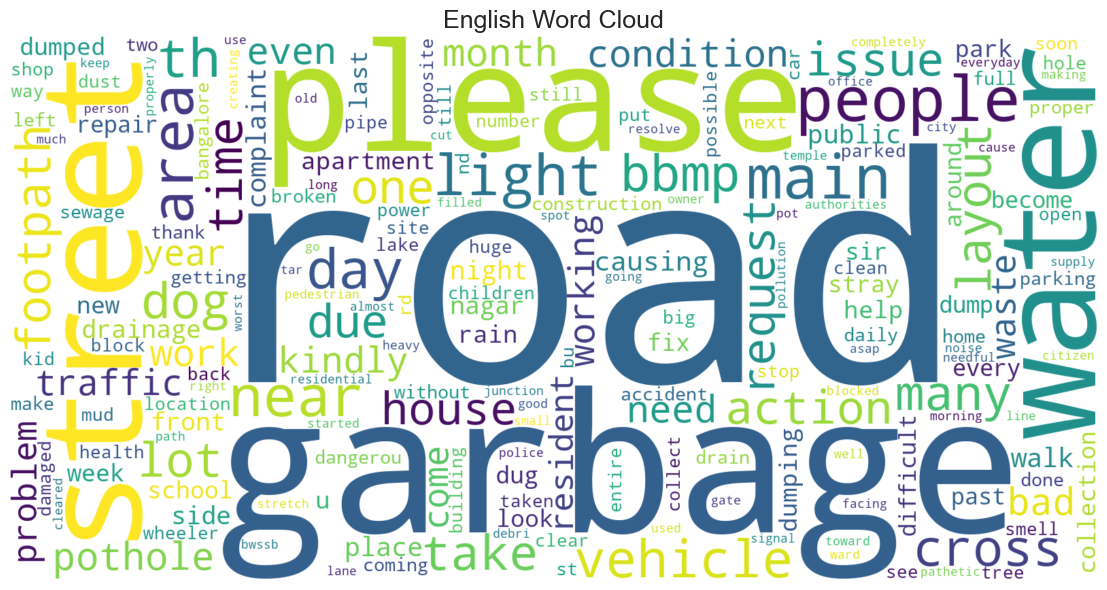

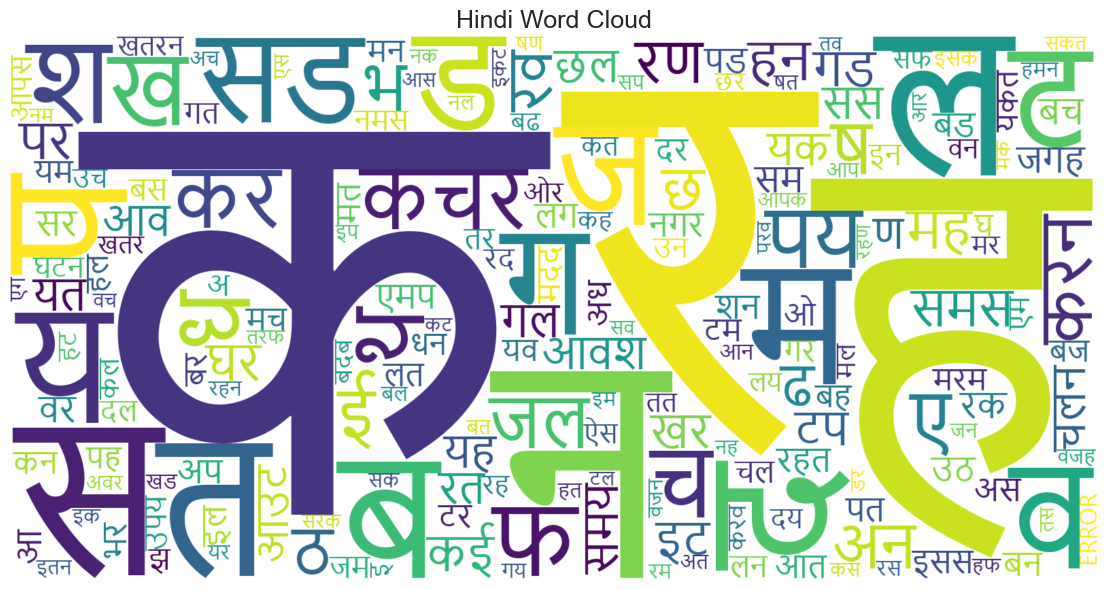

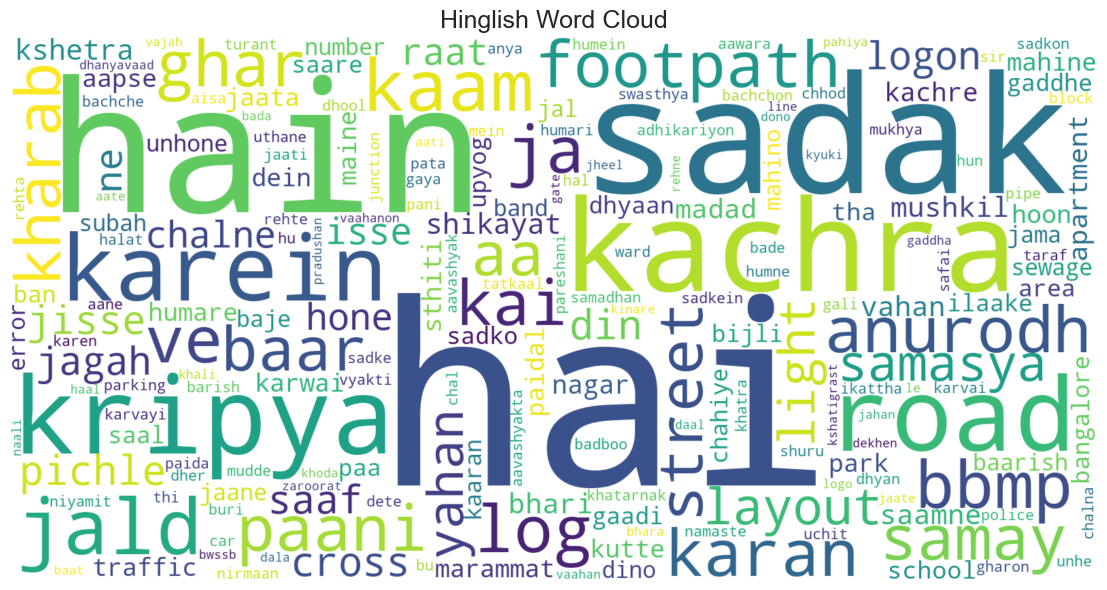

Word clouds saved successfully.


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import re
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')

# ==========================================
# LOAD DATASET
# ==========================================

df = pd.read_csv("CivicDataset.csv")

# Replace with your actual column names
# english_col = "English_Text"
hindi_col = "Hindi"
hinglish_col = "Hinglish"

# ==========================================
# STOPWORDS
# ==========================================

english_stopwords = set(stopwords.words('english'))

hindi_stopwords = {
    # Basic pronouns
    'है','हैं','था','थी','थे','हो','होगा','होगी','होंगे','हुआ','हुई','हुए',
    'का','की','के','को','में','पर','से','तक','लिए','द्वारा','कर','करके',
    'और','या','तथा','लेकिन','किन्तु','परंतु','अथवा','अर्थात','यानी','मतलब',
    'यह','ये','वह','वे','इस','उस','इन','उन','इसे','उसे','इन्हें','उन्हें',
    'मैं','हम','आप','तुम','तू','वो','जो','जिस','जिसे','जिसका','जिसकी','जिसके',
    'जिन','जिन्हें','जिनका','जिनकी','जिनके','मुझे','हमें','तुम्हें','आपको',
    'एक','दो','तीन','चार','पांच','छह','सात','आठ','नौ','दस','सौ','हजार',
    'न','ना','नहीं','मत','नही','नहि','नाही','मत्कर',
    'भी','ही','तो','तोही','हीही','भीतो','तोभी',
    'यदि','अगर','जब','तब','कब','जहाँ','वहाँ','जहां','वहां',
    'क्यों','कैसे','क्या','कौन','किस','किसका','किसकी','किसके',
    'किसी','किसीभी','कुछ','सभी','सब','हर','प्रत्येक','कोई','कोइ',
    'बहुत','अधिक','कम','काफी','लगभग','थोड़ा','थोड़ी','थोड़े','ज्यादा','ज़्यादा',
    'बाद','पहले','फिर','पुनः','दोबारा','फिरसे','फिरस','दुबारा',
    'अभी','अब','तभी','सदा','हमेशा','अक्सर','प्रायः','कभी','कभीकभी',
    'आज','कल','परसों','तरसों','आजकल','कलकल',
    'ऊपर','नीचे','आगे','पीछे','पास','दूर','नजदीक','निकट',
    'अंदर','बाहर','बीच','सामने','पीछे','बगल','आसपास',
    'कर','किया','किये','कीजिए','करना','करते','करती','करता','करेंगे','करूंगा',
    'करें','करो','करु','करू','करे','करेंगी','करोगे','करता','करती',
    'होना','होते','होती','होता','होंगे','होंगी','हुआ','हुई','हुए',
    'गया','गई','गए','जाता','जाती','जाते','जाओ','जाए','जाये',
    'रहा','रही','रहे','रहें','रहूंगा','रहेंगे',
    'बना','बनी','बने','बनाओ','बनाया','बनाई','बनाए',
    'लिया','लिए','ली','देना','दिया','दिए','दी','दो','दे',
    'रूप','तरह','प्रकार','संबंधित','सम्बंधित','अनुसार',
    'मात्र','सिर्फ','केवल','सिर्फ़','केवल','भर','मात्रा',
    'वाले','वाली','वाला','वालों','वाली','वाला',
    'सकता','सकती','सकते','सकूं','सके','सकी','सकूंगा',
    'चाहिए','चाहिये','चाहिये','चाही','चाहिये',
    'क्योंकि','इसलिए','अतः','अतएव','चूंकि','क्यूंकि',
    'दूसरा','दूसरी','दूसरे','दूसरो','दूसरों',
    'पहला','पहली','पहले','पहलो','पहलों',
    'इत्यादि','आदि','वगैरह','इत्यादी','वगेरह',
    'प्रति','बिना','साथ','सहित','समेत','सहित',
    'जनाब','श्री','श्रीमती','श्रीमान','श्रीमति',
    'लगता','लगती','लगते','लगा','लगी','लगे',
    'रखना','रखा','रखी','रखे','रखो','रखू',
    'चल','चलो','चलिए','चलें','चले','चलो',
    'उपरांत','पूर्व','पश्चात','उपरान्त','पश्चात',
    'वर्तमान','भविष्य','भूत','वर्तमान','भविष्य',
    'तुम्हारा','तुम्हारी','तुम्हारे','तुम्हारो',
    'हमारा','हमारी','हमारे','हमारो',
    'मेरा','मेरी','मेरे','मेरो',
    'अपना','अपनी','अपने','अपनो','अपनों',
    'यही','वही','इसी','उसी','यहीं','वहीं',
    'जैसा','जैसी','जैसे','जैसेकि',
    'वैसा','वैसी','वैसे','वैसाही',
    'पूरा','पूरी','पूरे','पुरा','पुरी','पुरे',
    'आधा','आधी','आधे','आधा',
    'लगातार','निरंतर','निरन्तर','लगातार',
    'जरूर','अवश्य','जरुर','जरूरी','अवश्य',
    'हर','हरएक','हरेक','प्रत्येक',
    'कभी','कभीकभी','कभी-कभी','कभिन',
    'केअंदर','केबाहर','केबीच','केसाथ',
    'जोकि','जोकी','जोके','जिसने','जिसने',
    'जिन्होंने','जिन्होने','जिसको','जिनको',
    'उसके','उनके','इसके','इनके',
    'उसपर','उनपर','इसपर','इनपर',
    'वगैरह','वगेरह','इत्यादि','आदि',
}

# Enhanced Hinglish stopwords (expanded)
hinglish_stopwords = {
    # Basic Hinglish
    'hai','hain','tha','thi','the','ho','hoga','hogi','honge','hua','hui','hue',
    'ka','ki','ke','ko','mein','main','me','par','pe','se','tak','liye','liyee','liyeh','dwara',
    'aur','ya','tatha','lekin','kintu','parantu','magar','but','or','and',
    'ye','yeh','yah','wo','woh','vo','is','us','in','un','ise','use','inhain','unhain',
    'mai','main','hum','ham','aap','tum','tu','vo','jo','jis','jise','jiska','jiski','jiske',
    'jin','jinhe','jinhein','jinhe','jinka','jinki','jinke',
    'mujhe','hume','hame','tumhe','aapko','isko','usko','unko','inko','unhain',
    'ek','do','teen','char','paanch','che','saat','ath','nau','das','so','hazar',
    'na','nahi','nahin','mat','nahi','nahin','naheen','matt',
    'bhi','hi','to','toh','tohi','to bhi','hi toh',
    'agar','yadi','jab','tab','kab','jaha','waha','jahaan','wahaan','jahape','wahape',
    'kya','kyaa','kaun','kaise','kyun','kyon','kaisa','kaisi','kaise',
    'kisi','kisiko','kiska','kiski','kiske','kuch','kuchh',
    'sab','sabhi','har','pratyek','koi','koee','koyi',
    'bahut','zyada','jada','adhik','kam','kaafi','lagbhag','thora','thori','thore','jayada','jyaada',
    'baad','pehle','fir','phir','dobara','firse','duabara','phirse',
    'abhi','ab','tabhi','sada','hamesha','aksar','kabhi','kabhi kabhi',
    'aaj','kal','parson','ajkal','kal','parson',
    'upar','neeche','aage','peeche','paas','door','nazdeek','nazdik',
    'andar','bahar','beech','samne','pichhe','bagal','aaspaas',
    'kar','karo','karna','kiya','kiye','karne','karta','karti','karte','karenge','karunga',
    'kare','karen','karoge','karta','karti','karte','karu','karega','karegi',
    'hona','hote','hoti','hota','honge','hongi','hota','hoti','hote',
    'gaya','gayi','gaye','jata','jati','jate','jao','jaaye','jaye',
    'raha','rahi','rahe','rahenge','raha','rahi','rahe',
    'bana','bani','bane','banao','banaya','banai','banaye','banayen',
    'liya','liye','li','dena','diya','diye','di','do','de','lena','lena',
    'roop','tarah','prakar','sambandhit','anusar',
    'matra','sirf','keval','bhar','sirf','keval',
    'wale','wali','wala','walo','walon',
    'sakta','sakti','sakte','sakoon','sake','saki','sakunga',
    'chahiye','chahiyeh','chahi','chahie','chahiyee',
    'kyunki','isliye','atah','atev','chunki','kyunki',
    'dusra','dusri','dusre','dusro','dusron',
    'pehla','pehli','pehle','pehlo','pehlon',
    'etc','wagairah','vagera','wagera','wagerah','ityadi','adi',
    'prati','bina','saath','sath','sahit','sahit',
    'janab','shri','shrimati','shriman',
    'lagta','lagti','lagte','laga','lagi','lage',
    'rakhna','rakha','rakhi','rakhe','rakho','rakhu',
    'chalo','chaliye','chale','chaliye','chalen',
    'tumhara','tumhari','tumhare','tumharo',
    'hamara','hamari','hamare','hamaro',
    'mera','meri','mere','mero',
    'apna','apni','apne','apno','apnon',
    'yahi','wahi','isi','usi','yahin','wahin',
    'jaise','jaisa','jaisi','jaiseki',
    'waise','waisa','waisi','waisahi',
    'poora','poori','poore','pura','puri','pure',
    'aadha','aadhi','aadhe','aadha',
    'lagatar','nirantar','lagaatar',
    'zarur','jarur','avashya','jaroor','zaroor','zaruri',
    'har','harek','pratyek',
    'kabhi','kabhi kabhi','kabhi-kabhi','kabhi kabhi',
    'andar','bahar','beech','saath','sath',
    'joki','jiske','jisne','jinhone','jisko','jinko',
    'uske','unke','iske','inke',
    'uspar','unpar','ispar','inpar',
    # English words commonly used in Hinglish
    'please','plz','pls','okay','ok','haan','han','ji','sir','madam',
    'bhai','bhaiya','didi','are','arre','abe','hello','hi','hey',
    'good','bad','very','much','many','more','less','few','some',
    'all','every','any','can','could','would','should','will','shall',
    'am','is','are','was','were','be','been','being','do','does','did',
    'have','has','had','from','for','of','on','at','by','with','without',
    'into','onto','about','during','before','after','because','therefore',
    'then','than','that','this','these','those','it','its','their',
    'our','your','my','mine','yours','ours','him','her','them',
    'such','same','another','already','still','ever','never','always',
    'sometimes','often','maybe','perhaps','also','too','as','so',
    'just','only','well','now','then','there','here','where',
    'like','unlike','along','while','among','between','across',
    'however','although','though','whereas','meanwhile','finally',
    'first','second','third','next','last','finally','meanwhile',
    'further','furthermore','moreover','accordingly','consequently',
    'namely','specifically','generally','usually','eventually',
    'rather','quite','almost','mostly','sometimes','hardly',
    'anyway','anyways','whatever','whichever','whoever',
    'even','evenif','eventhough','again','againandagain',
    'ago','before','afterwards','afterward','meanwhile',
    'ago','before','afterwards','afterward','meanwhile',
    # Additional common Hinglish words
    'accha','acha','theek','thik','chalo','chale','chaliye',
    'kya','kaise','kyun','kab','kaha','kaun','kiska','kiski',
    'nahi','na','mat','haan','han','yes','no','sahi','galat',
    'bas','bass','yaar','dost','friend','buddy','man','guy',
    'dekho','dekh','sun','suno','samajh','samajho','jao','jaiye',
    'ao','aao','aaiye','aaye','aayen','chalo','chaliye',
    'bat','batao','bata','bolo','bol','karo','kar',
    'acha','sahi','galat','achha','thik','ok','okay','alright',
    'ready','set','go','start','stop','wait','ruk','ruko',
    'koi','koee','kuch','kuchh','thoda','thodi','thode','zyada',
    'kam','bahut','kaafi','pura','poora','sara','saara','sab',
    'mil','milo','milte','milen','aapas','mein','main','hum',
    'tum','vo','ye','yah','wo','woh','yeh','voh',
}

# ==========================================
# CLEANING FUNCTIONS
# ==========================================

def clean_english(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)

    words = [
        word for word in text.split()
        if word not in english_stopwords
    ]

    return " ".join(words)

def clean_hindi(text):
    text = str(text)

    words = [
        word for word in text.split()
        if word not in hindi_stopwords
    ]

    return " ".join(words)

def clean_hinglish(text):
    text = str(text).lower()

    words = [
        word for word in text.split()
        if word not in hinglish_stopwords
    ]

    return " ".join(words)

# ==========================================
# COMBINE TEXT
# ==========================================

english_text = " ".join((df["complaint_title"]+df["text_en"]).astype(str))
hindi_text = " ".join(df[hindi_col].astype(str))
hinglish_text = " ".join(df[hinglish_col].astype(str))

english_text = clean_english(english_text)
hindi_text = clean_hindi(hindi_text)
hinglish_text = clean_hinglish(hinglish_text)

# ==========================================
# HINDI FONT PATH
# ==========================================

# Windows Example
font_path = r"C:\Windows\Fonts\Nirmala.ttc"

# Alternative:
# font_path = r"C:\Windows\Fonts\mangal.ttf"

# ==========================================
# CREATE WORD CLOUDS
# ==========================================

datasets = {
    "English": (english_text, None),
    "Hindi": (hindi_text, font_path),
    "Hinglish": (hinglish_text, None)
}

for language, (text, font) in datasets.items():

    wc = WordCloud(
        width=1600,
        height=800,
        background_color='white',
        max_words=200,
        font_path=font,
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12,6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"{language} Word Cloud", fontsize=18)
    plt.tight_layout()

    plt.savefig(
        f"{language}_WordCloud.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

print("Word clouds saved successfully.")

In [12]:
import os

font_dir = r"C:\Windows\Fonts"

for font in os.listdir(font_dir):
    if "mangal" in font.lower() or "nirmala" in font.lower():
        print(font)

Nirmala.ttc


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\CH.SC.U4CSE23160\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


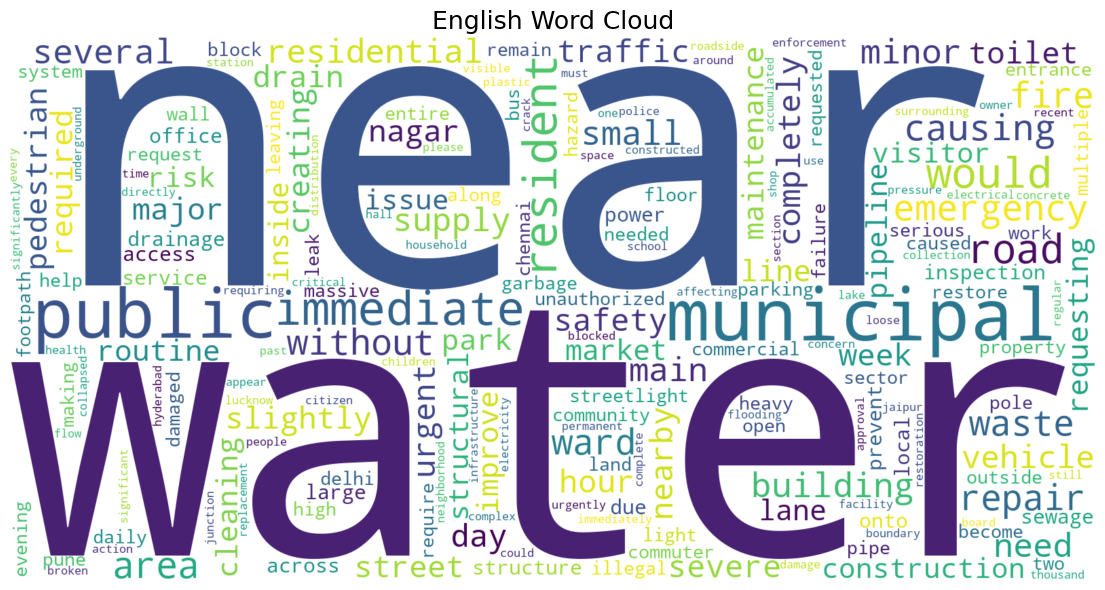

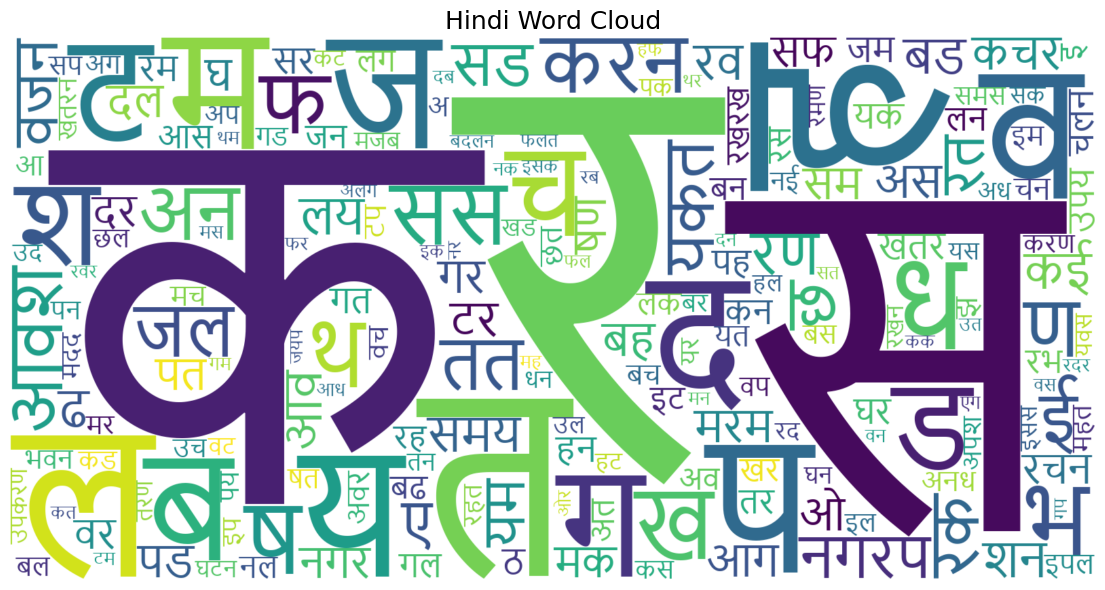

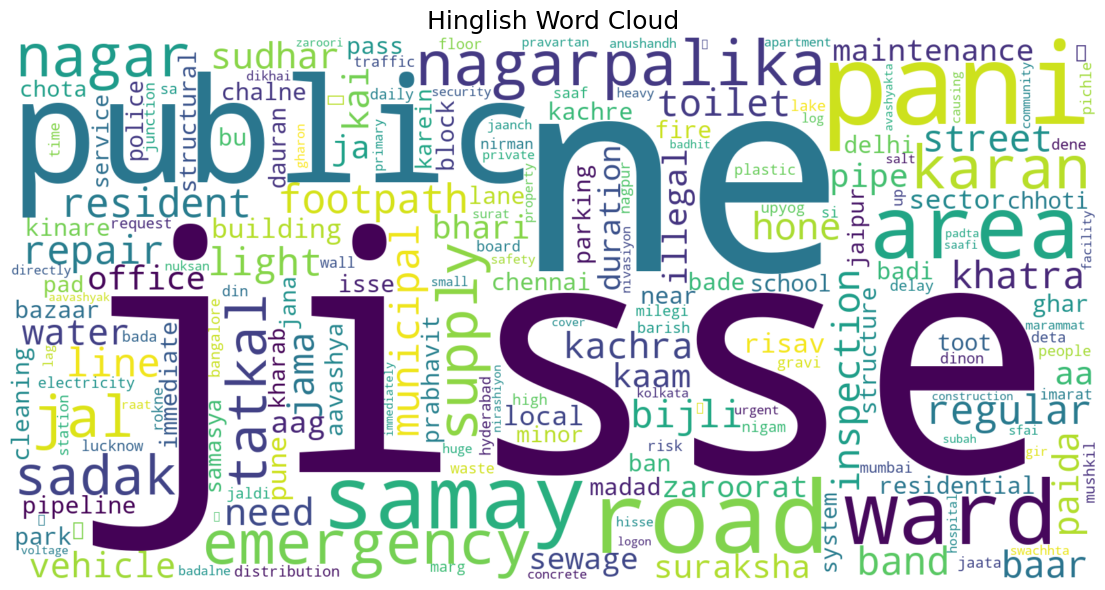

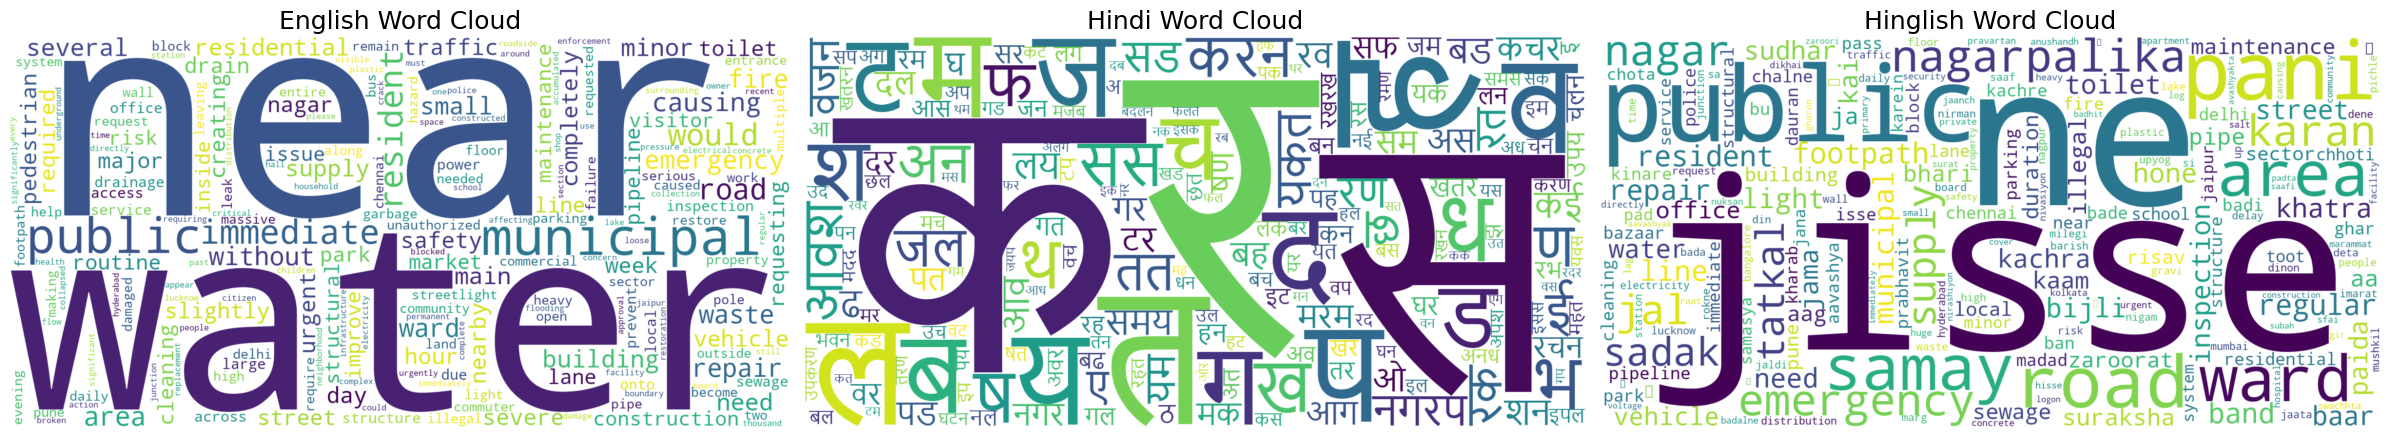

Word clouds saved successfully.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import re
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')

# ==========================================
# LOAD DATASET
# ==========================================

df = pd.read_csv("complaints_hinglish.csv")

# Replace with your actual column names
hindi_col = "Text_hi"
hinglish_col = "Text_hinglish"

# ==========================================
# STOPWORDS (your existing stopwords remain the same)
# ==========================================

english_stopwords = set(stopwords.words('english'))

hindi_stopwords = {
    # Basic pronouns
    'है','हैं','था','थी','थे','हो','होगा','होगी','होंगे','हुआ','हुई','हुए',
    'का','की','के','को','में','पर','से','तक','लिए','द्वारा','कर','करके',
    'और','या','तथा','लेकिन','किन्तु','परंतु','अथवा','अर्थात','यानी','मतलब',
    'यह','ये','वह','वे','इस','उस','इन','उन','इसे','उसे','इन्हें','उन्हें',
    'मैं','हम','आप','तुम','तू','वो','जो','जिस','जिसे','जिसका','जिसकी','जिसके',
    'जिन','जिन्हें','जिनका','जिनकी','जिनके','मुझे','हमें','तुम्हें','आपको',
    'एक','दो','तीन','चार','पांच','छह','सात','आठ','नौ','दस','सौ','हजार',
    'न','ना','नहीं','मत','नही','नहि','नाही','मत्कर',
    'भी','ही','तो','तोही','हीही','भीतो','तोभी',
    'यदि','अगर','जब','तब','कब','जहाँ','वहाँ','जहां','वहां',
    'क्यों','कैसे','क्या','कौन','किस','किसका','किसकी','किसके',
    'किसी','किसीभी','कुछ','सभी','सब','हर','प्रत्येक','कोई','कोइ',
    'बहुत','अधिक','कम','काफी','लगभग','थोड़ा','थोड़ी','थोड़े','ज्यादा','ज़्यादा',
    'बाद','पहले','फिर','पुनः','दोबारा','फिरसे','फिरस','दुबारा',
    'अभी','अब','तभी','सदा','हमेशा','अक्सर','प्रायः','कभी','कभीकभी',
    'आज','कल','परसों','तरसों','आजकल','कलकल',
    'ऊपर','नीचे','आगे','पीछे','पास','दूर','नजदीक','निकट',
    'अंदर','बाहर','बीच','सामने','पीछे','बगल','आसपास',
    'कर','किया','किये','कीजिए','करना','करते','करती','करता','करेंगे','करूंगा',
    'करें','करो','करु','करू','करे','करेंगी','करोगे','करता','करती',
    'होना','होते','होती','होता','होंगे','होंगी','हुआ','हुई','हुए',
    'गया','गई','गए','जाता','जाती','जाते','जाओ','जाए','जाये',
    'रहा','रही','रहे','रहें','रहूंगा','रहेंगे',
    'बना','बनी','बने','बनाओ','बनाया','बनाई','बनाए',
    'लिया','लिए','ली','देना','दिया','दिए','दी','दो','दे',
    'रूप','तरह','प्रकार','संबंधित','सम्बंधित','अनुसार',
    'मात्र','सिर्फ','केवल','सिर्फ़','केवल','भर','मात्रा',
    'वाले','वाली','वाला','वालों','वाली','वाला',
    'सकता','सकती','सकते','सकूं','सके','सकी','सकूंगा',
    'चाहिए','चाहिये','चाहिये','चाही','चाहिये',
    'क्योंकि','इसलिए','अतः','अतएव','चूंकि','क्यूंकि',
    'दूसरा','दूसरी','दूसरे','दूसरो','दूसरों',
    'पहला','पहली','पहले','पहलो','पहलों',
    'इत्यादि','आदि','वगैरह','इत्यादी','वगेरह',
    'प्रति','बिना','साथ','सहित','समेत','सहित',
    'जनाब','श्री','श्रीमती','श्रीमान','श्रीमति',
    'लगता','लगती','लगते','लगा','लगी','लगे',
    'रखना','रखा','रखी','रखे','रखो','रखू',
    'चल','चलो','चलिए','चलें','चले','चलो',
    'उपरांत','पूर्व','पश्चात','उपरान्त','पश्चात',
    'वर्तमान','भविष्य','भूत','वर्तमान','भविष्य',
    'तुम्हारा','तुम्हारी','तुम्हारे','तुम्हारो',
    'हमारा','हमारी','हमारे','हमारो',
    'मेरा','मेरी','मेरे','मेरो',
    'अपना','अपनी','अपने','अपनो','अपनों',
    'यही','वही','इसी','उसी','यहीं','वहीं',
    'जैसा','जैसी','जैसे','जैसेकि',
    'वैसा','वैसी','वैसे','वैसाही',
    'पूरा','पूरी','पूरे','पुरा','पुरी','पुरे',
    'आधा','आधी','आधे','आधा',
    'लगातार','निरंतर','निरन्तर','लगातार',
    'जरूर','अवश्य','जरुर','जरूरी','अवश्य',
    'हर','हरएक','हरेक','प्रत्येक',
    'कभी','कभीकभी','कभी-कभी','कभिन',
    'केअंदर','केबाहर','केबीच','केसाथ',
    'जोकि','जोकी','जोके','जिसने','जिसने',
    'जिन्होंने','जिन्होने','जिसको','जिनको',
    'उसके','उनके','इसके','इनके',
    'उसपर','उनपर','इसपर','इनपर',
    'वगैरह','वगेरह','इत्यादि','आदि',
}

hinglish_stopwords = {
    # Basic Hinglish
    'hai','hain','tha','thi','the','ho','hoga','hogi','honge','hua','hui','hue',
    'ka','ki','ke','ko','mein','main','me','par','pe','se','tak','liye','liyee','liyeh','dwara',
    'aur','ya','tatha','lekin','kintu','parantu','magar','but','or','and',
    'ye','yeh','yah','wo','woh','vo','is','us','in','un','ise','use','inhain','unhain',
    'mai','main','hum','ham','aap','tum','tu','vo','jo','jis','jise','jiska','jiski','jiske',
    'jin','jinhe','jinhein','jinhe','jinka','jinki','jinke',
    'mujhe','hume','hame','tumhe','aapko','isko','usko','unko','inko','unhain',
    'ek','do','teen','char','paanch','che','saat','ath','nau','das','so','hazar',
    'na','nahi','nahin','mat','nahi','nahin','naheen','matt',
    'bhi','hi','to','toh','tohi','to bhi','hi toh',
    'agar','yadi','jab','tab','kab','jaha','waha','jahaan','wahaan','jahape','wahape',
    'kya','kyaa','kaun','kaise','kyun','kyon','kaisa','kaisi','kaise',
    'kisi','kisiko','kiska','kiski','kiske','kuch','kuchh',
    'sab','sabhi','har','pratyek','koi','koee','koyi',
    'bahut','zyada','jada','adhik','kam','kaafi','lagbhag','thora','thori','thore','jayada','jyaada',
    'baad','pehle','fir','phir','dobara','firse','duabara','phirse',
    'abhi','ab','tabhi','sada','hamesha','aksar','kabhi','kabhi kabhi',
    'aaj','kal','parson','ajkal','kal','parson',
    'upar','neeche','aage','peeche','paas','door','nazdeek','nazdik',
    'andar','bahar','beech','samne','pichhe','bagal','aaspaas',
    'kar','karo','karna','kiya','kiye','karne','karta','karti','karte','karenge','karunga',
    'kare','karen','karoge','karta','karti','karte','karu','karega','karegi',
    'hona','hote','hoti','hota','honge','hongi','hota','hoti','hote',
    'gaya','gayi','gaye','jata','jati','jate','jao','jaaye','jaye',
    'raha','rahi','rahe','rahenge','raha','rahi','rahe',
    'bana','bani','bane','banao','banaya','banai','banaye','banayen',
    'liya','liye','li','dena','diya','diye','di','do','de','lena','lena',
    'roop','tarah','prakar','sambandhit','anusar',
    'matra','sirf','keval','bhar','sirf','keval',
    'wale','wali','wala','walo','walon',
    'sakta','sakti','sakte','sakoon','sake','saki','sakunga',
    'chahiye','chahiyeh','chahi','chahie','chahiyee',
    'kyunki','isliye','atah','atev','chunki','kyunki',
    'dusra','dusri','dusre','dusro','dusron',
    'pehla','pehli','pehle','pehlo','pehlon',
    'etc','wagairah','vagera','wagera','wagerah','ityadi','adi',
    'prati','bina','saath','sath','sahit','sahit',
    'janab','shri','shrimati','shriman',
    'lagta','lagti','lagte','laga','lagi','lage',
    'rakhna','rakha','rakhi','rakhe','rakho','rakhu',
    'chalo','chaliye','chale','chaliye','chalen',
    'tumhara','tumhari','tumhare','tumharo',
    'hamara','hamari','hamare','hamaro',
    'mera','meri','mere','mero',
    'apna','apni','apne','apno','apnon',
    'yahi','wahi','isi','usi','yahin','wahin',
    'jaise','jaisa','jaisi','jaiseki',
    'waise','waisa','waisi','waisahi',
    'poora','poori','poore','pura','puri','pure',
    'aadha','aadhi','aadhe','aadha',
    'lagatar','nirantar','lagaatar',
    'zarur','jarur','avashya','jaroor','zaroor','zaruri',
    'har','harek','pratyek',
    'kabhi','kabhi kabhi','kabhi-kabhi','kabhi kabhi',
    'andar','bahar','beech','saath','sath',
    'joki','jiske','jisne','jinhone','jisko','jinko',
    'uske','unke','iske','inke',
    'uspar','unpar','ispar','inpar',
    # English words commonly used in Hinglish
    'please','plz','pls','okay','ok','haan','han','ji','sir','madam',
    'bhai','bhaiya','didi','are','arre','abe','hello','hi','hey',
    'good','bad','very','much','many','more','less','few','some',
    'all','every','any','can','could','would','should','will','shall',
    'am','is','are','was','were','be','been','being','do','does','did',
    'have','has','had','from','for','of','on','at','by','with','without',
    'into','onto','about','during','before','after','because','therefore',
    'then','than','that','this','these','those','it','its','their',
    'our','your','my','mine','yours','ours','him','her','them',
    'such','same','another','already','still','ever','never','always',
    'sometimes','often','maybe','perhaps','also','too','as','so',
    'just','only','well','now','then','there','here','where',
    'like','unlike','along','while','among','between','across',
    'however','although','though','whereas','meanwhile','finally',
    'first','second','third','next','last','finally','meanwhile',
    'further','furthermore','moreover','accordingly','consequently',
    'namely','specifically','generally','usually','eventually',
    'rather','quite','almost','mostly','sometimes','hardly',
    'anyway','anyways','whatever','whichever','whoever',
    'even','evenif','eventhough','again','againandagain',
    'ago','before','afterwards','afterward','meanwhile',
    'accha','acha','theek','thik','chalo','chale','chaliye',
    'kya','kaise','kyun','kab','kaha','kaun','kiska','kiski',
    'nahi','na','mat','haan','han','yes','no','sahi','galat',
    'bas','bass','yaar','dost','friend','buddy','man','guy',
    'dekho','dekh','sun','suno','samajh','samajho','jao','jaiye',
    'ao','aao','aaiye','aaye','aayen','chalo','chaliye',
    'bat','batao','bata','bolo','bol','karo','kar',
    'acha','sahi','galat','achha','thik','ok','okay','alright',
    'ready','set','go','start','stop','wait','ruk','ruko',
    'koi','koee','kuch','kuchh','thoda','thodi','thode','zyada',
    'kam','bahut','kaafi','pura','poora','sara','saara','sab',
    'mil','milo','milte','milen','aapas','mein','main','hum',
    'tum','vo','ye','yah','wo','woh','yeh','voh',
}

# ==========================================
# IMPROVED CLEANING FUNCTIONS
# ==========================================

def clean_english(text):
    text = str(text).lower()
    # Remove everything except alphabets and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Split and filter stopwords
    words = text.split()
    filtered_words = [word for word in words if word not in english_stopwords and len(word) > 1]
    return " ".join(filtered_words)

def clean_hindi(text):
    text = str(text)
    # Remove punctuation and digits (keep Devanagari and spaces)
    text = re.sub(r'[^\u0900-\u097F\s]', ' ', text)
    # Split and filter
    words = text.split()
    filtered_words = [word for word in words if word not in hindi_stopwords and len(word) > 1]
    return " ".join(filtered_words)

def clean_hinglish(text):
    text = str(text).lower()
    # Remove punctuation and digits (keep Devanagari + Latin letters + spaces)
    text = re.sub(r'[^a-z\u0900-\u097F\s]', ' ', text)
    # Split and filter
    words = text.split()
    filtered_words = [word for word in words if word not in hinglish_stopwords and len(word) > 1]
    return " ".join(filtered_words)

# ==========================================
# COMBINE TEXT (FIX: Use correct column names)
# ==========================================

# Make sure your DataFrame has these columns
english_text = " ".join(df["Text_en"].astype(str))  # Use actual column name
hindi_text = " ".join(df[hindi_col].astype(str))
hinglish_text = " ".join(df[hinglish_col].astype(str))

english_text = clean_english(english_text)
hindi_text = clean_hindi(hindi_text)
hinglish_text = clean_hinglish(hinglish_text)

# ==========================================
# HINDI FONT PATH
# ==========================================

font_path = r"C:\Windows\Fonts\Nirmala.ttc"

# ==========================================
# CREATE WORD CLOUDS
# ==========================================

wordclouds = {}

datasets = {
    "English": (english_text, None),
    "Hindi": (hindi_text, font_path),
    "Hinglish": (hinglish_text, None)
}

for language, (text, font) in datasets.items():
    # Pass stopwords to WordCloud explicitly
    if language == "English":
        stopwords_set = english_stopwords
    elif language == "Hindi":
        stopwords_set = hindi_stopwords
    else:  # Hinglish
        stopwords_set = hinglish_stopwords

    wc = WordCloud(
        width=1600,
        height=800,
        background_color='white',
        max_words=200,
        font_path=font,
        stopwords=stopwords_set,  # <-- CRITICAL FIX
        collocations=False
    ).generate(text)

    wordclouds[language] = wc

    plt.figure(figsize=(12,6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"{language} Word Cloud", fontsize=18)
    plt.tight_layout()
    plt.savefig(f"{language}_WordCloud.png", dpi=300, bbox_inches='tight')
    plt.show()

# ==========================================
# COMBINED PLOT
# ==========================================

n = len(wordclouds)
fig, axes = plt.subplots(1, n, figsize=(8 * n, 8))

if n == 1:
    axes = [axes]

for ax, (language, wc) in zip(axes, wordclouds.items()):
    ax.imshow(wc, interpolation='bilinear')
    ax.axis("off")
    ax.set_title(f"{language} Word Cloud", fontsize=18)

plt.tight_layout()
plt.savefig("Combined_WordClouds.png", dpi=300, bbox_inches='tight')
plt.show()

print("Word clouds saved successfully.")

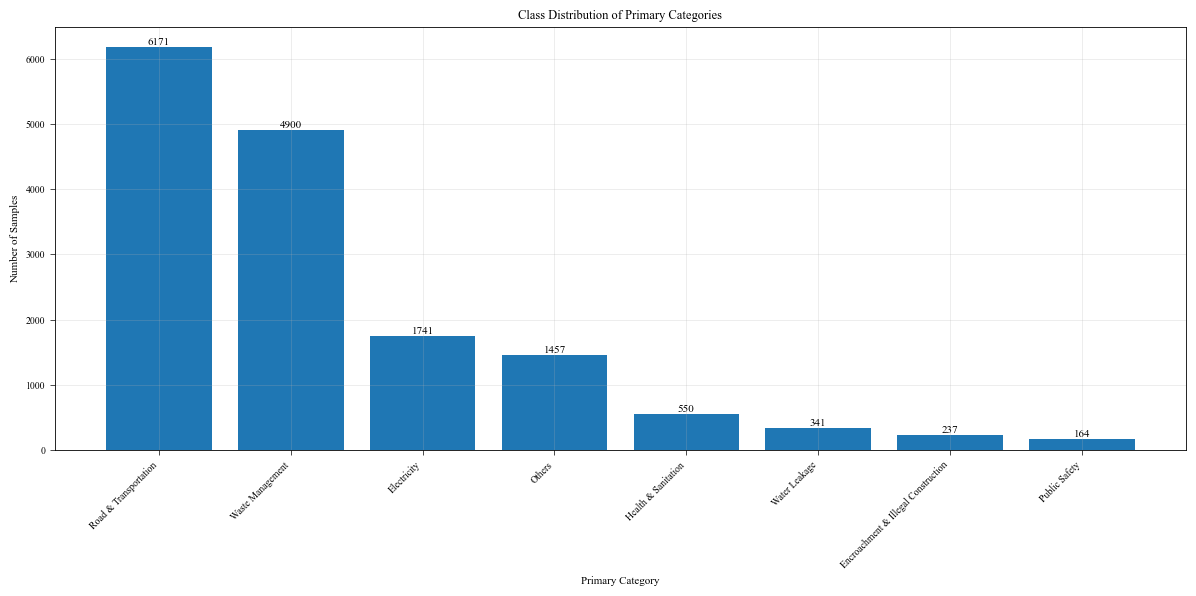

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("CivicDataset.csv")

primary_counts = (
    df["category_primary"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

bars = plt.bar(
    primary_counts.index,
    primary_counts.values
)

plt.title("Class Distribution of Primary Categories")
plt.xlabel("Primary Category")
plt.ylabel("Number of Samples")

plt.xticks(rotation=45, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    "Primary_Category_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

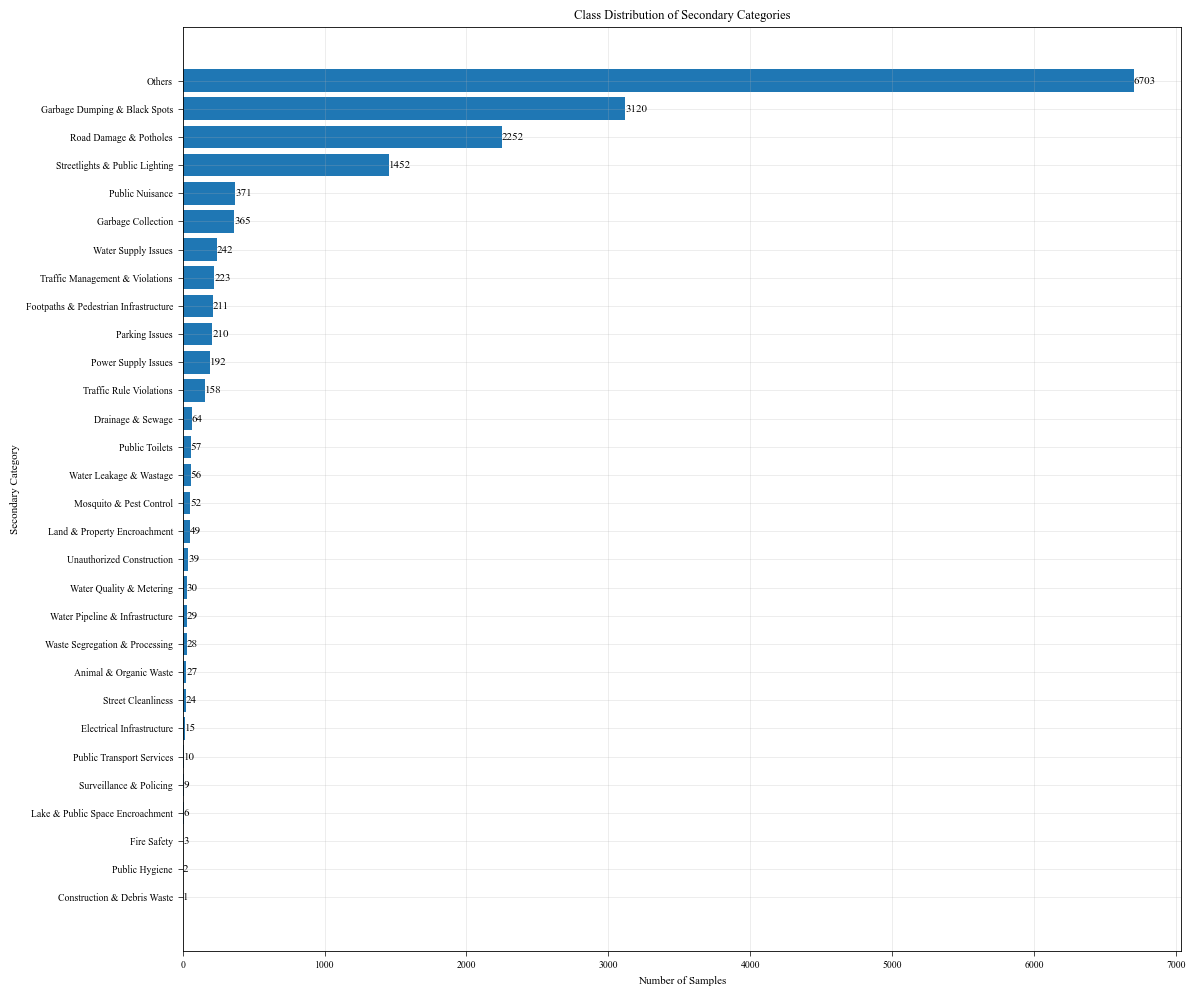

In [13]:
secondary_counts = (
    df["category_secondary"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12,10))

bars = plt.barh(
    secondary_counts.index,
    secondary_counts.values
)

plt.title("Class Distribution of Secondary Categories")
plt.xlabel("Number of Samples")
plt.ylabel("Secondary Category")

for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        str(int(bar.get_width())),
        va='center'
    )

plt.tight_layout()

plt.savefig(
    "Secondary_Category_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

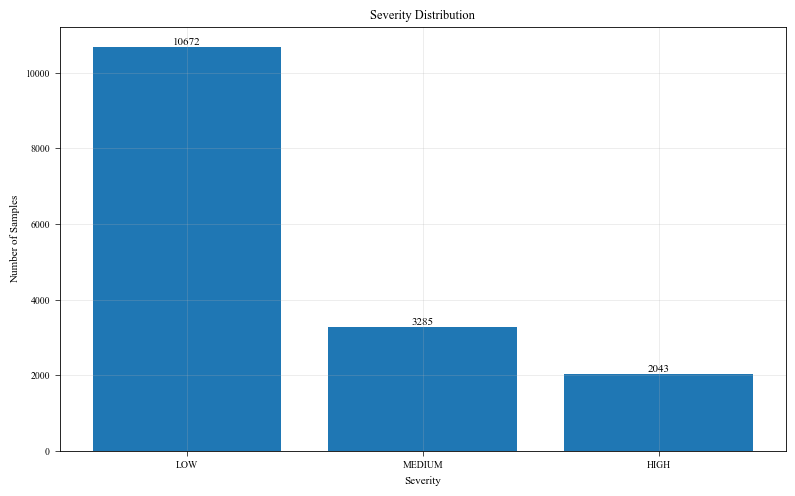

In [14]:
severity_counts = (
    df["severity"]
    .value_counts()
)

plt.figure(figsize=(8,5))

bars = plt.bar(
    severity_counts.index,
    severity_counts.values
)

plt.title("Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Samples")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    "Severity_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\CH.SC.U4CSE23160\AppData\Local\Temp\ipykernel_13996\501073250.py:173: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.5)


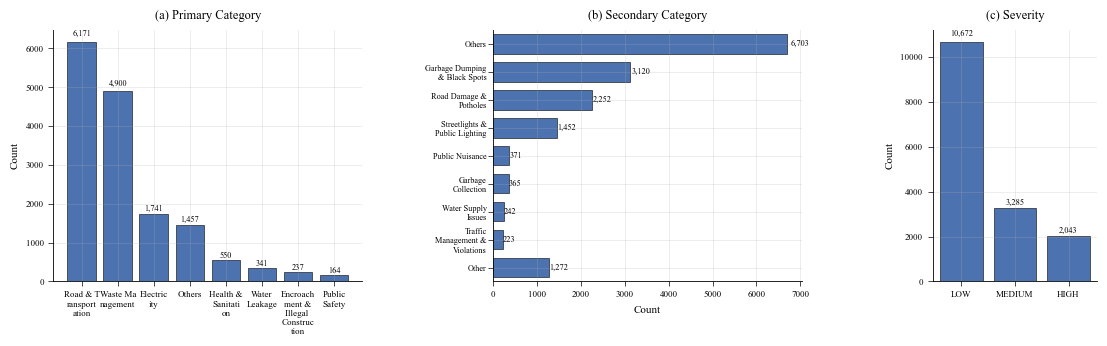

Figure saved successfully!


In [25]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import textwrap

# ==========================================
# IEEE-ACCESS STYLE SETTINGS
# ==========================================

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
})

BAR_COLOR = "#4C72B0"

def top_n_with_other(counts: pd.Series, n: int) -> pd.Series:
    if len(counts) <= n:
        return counts
    top = counts.iloc[:n]
    other_total = counts.iloc[n:].sum()
    return pd.concat([top, pd.Series({"Other": other_total})])

def wrap_labels(labels, width=10):
    wrapped = []
    for label in labels:
        label_str = str(label)
        if len(label_str) > width:
            wrapped.append("\n".join(textwrap.wrap(label_str, width=width)))
        else:
            wrapped.append(label_str)
    return wrapped

# ==========================================
# CREATE FIGURE WITH AUTO-ADJUSTING HEIGHT
# ==========================================

TOP_N_PRIMARY = 8
TOP_N_SECONDARY = 8

# Count number of categories to dynamically adjust height
primary_counts = df["category_primary"].value_counts()
if len(primary_counts) > TOP_N_PRIMARY:
    primary_counts = top_n_with_other(primary_counts, TOP_N_PRIMARY)

secondary_counts_full = df["category_secondary"].value_counts()
secondary_counts = top_n_with_other(secondary_counts_full, TOP_N_SECONDARY)

# CRITICAL FIX: Reverse the order so highest values appear at the top
secondary_counts = secondary_counts.iloc[::-1]  # Reverse the Series

# Dynamic figure height based on number of bars
max_bars = max(len(primary_counts), len(secondary_counts), len(df["severity"].value_counts()))
fig_height = max(3.5, 0.3 * max_bars + 1.0)

fig = plt.figure(figsize=(12.0, fig_height))

# Use GridSpec with adjusted spacing
gs = fig.add_gridspec(
    1, 3, 
    width_ratios=[1.5, 1.5, 0.8],
    wspace=0.5,
    left=0.08,
    right=0.95,
    bottom=0.2,
    top=0.88
)

ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[0, 2])

# ------------------------------------------
# (a) Primary category distribution
# ------------------------------------------
bars_a = ax_a.bar(
    primary_counts.index.astype(str),
    primary_counts.values,
    color=BAR_COLOR,
    edgecolor="black",
    linewidth=0.4,
)

ax_a.set_title("(a) Primary Category", pad=8)
ax_a.set_ylabel("Count")

# Wrap labels
wrapped_labels_a = wrap_labels(primary_counts.index.astype(str), width=8)
ax_a.set_xticks(range(len(wrapped_labels_a)))
ax_a.set_xticklabels(wrapped_labels_a, rotation=0, ha='center')

# Value labels
for bar, val in zip(bars_a, primary_counts.values):
    height = bar.get_height()
    ax_a.text(bar.get_x() + bar.get_width()/2., height + height*0.02,
              f'{val:,}', ha='center', va='bottom', fontsize=6)

# ------------------------------------------
# (b) Secondary category distribution - FIXED ORDER
# ------------------------------------------
bar_height = min(0.7, 10.0 / len(secondary_counts))

bars_b = ax_b.barh(
    secondary_counts.index.astype(str),
    secondary_counts.values,
    color=BAR_COLOR,
    edgecolor="black",
    linewidth=0.4,
    height=bar_height,
)

wrapped_labels_b = wrap_labels(secondary_counts.index.astype(str), width=15)
ax_b.set_yticks(range(len(wrapped_labels_b)))
ax_b.set_yticklabels(wrapped_labels_b, fontsize=6)

# ax_b.invert_yaxis()  # REMOVED - no longer needed since data is reversed

ax_b.set_title(f"(b) Secondary Category", pad=8)
ax_b.set_xlabel("Count")
ax_b.tick_params(axis="y", pad=1)

# Value labels
for bar, val in zip(bars_b, secondary_counts.values):
    width = bar.get_width()
    ax_b.text(width + width*0.01, bar.get_y() + bar.get_height()/2.,
              f'{val:,}', ha='left', va='center', fontsize=6)

# ------------------------------------------
# (c) Severity distribution
# ------------------------------------------
severity_counts = df["severity"].value_counts()
bars_c = ax_c.bar(
    severity_counts.index.astype(str),
    severity_counts.values,
    color=BAR_COLOR,
    edgecolor="black",
    linewidth=0.4,
)
ax_c.set_title("(c) Severity", pad=8)
ax_c.set_ylabel("Count")

wrapped_labels_c = wrap_labels(severity_counts.index.astype(str), width=6)
ax_c.set_xticks(range(len(wrapped_labels_c)))
ax_c.set_xticklabels(wrapped_labels_c, rotation=0, ha='center')

for bar, val in zip(bars_c, severity_counts.values):
    height = bar.get_height()
    ax_c.text(bar.get_x() + bar.get_width()/2., height + height*0.02,
              f'{val:,}', ha='center', va='bottom', fontsize=6)

# ------------------------------------------
# Cleanup
# ------------------------------------------
for ax in (ax_a, ax_b, ax_c):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.05, y=0.05)

ax_b.set_ylim(-0.5, len(secondary_counts) - 0.5)

plt.tight_layout(pad=0.5)
plt.savefig(
    "Class_Imbalance_Analysis.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05,
)
plt.show()

print("Figure saved successfully!")

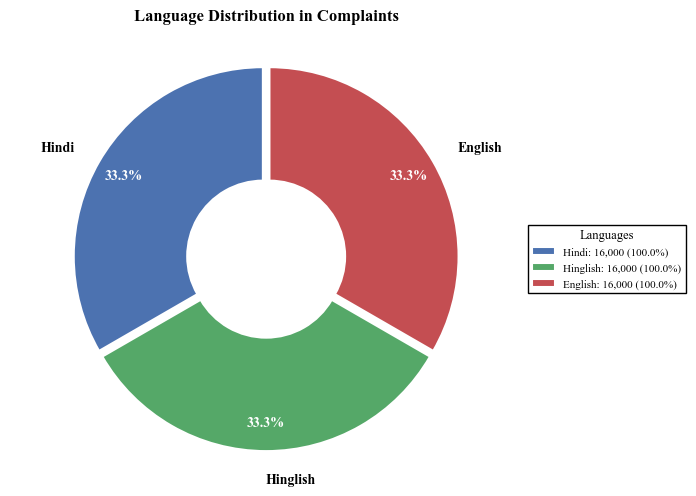


LANGUAGE DISTRIBUTION STATISTICS

Total samples: 16,000

Language Distribution (based on non-empty columns):
  Hindi: 16,000 (100.0%)
  Hinglish: 16,000 (100.0%)
  English: 16,000 (100.0%)


In [34]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd

# ==========================================
# IEEE-ACCESS STYLE SETTINGS
# ==========================================
df = pd.read_csv('CivicDataset.csv')
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
})

# ==========================================
# COUNT LANGUAGE DISTRIBUTION FROM SEPARATE COLUMNS
# ==========================================

# Count non-empty entries in each language column
hindi_count = df["Hindi"].notna().sum()
hinglish_count = df["Hinglish"].notna().sum()
english_count = df["text_en"].notna().sum()

# Create a Series for language counts
language_counts = pd.Series({
    "Hindi": hindi_count,
    "Hinglish": hinglish_count,
    "English": english_count
})

# Remove any language with 0 count
language_counts = language_counts[language_counts > 0]

# ==========================================
# CREATE DONUT CHART
# ==========================================

fig, ax = plt.subplots(figsize=(7, 5))

# Colors
colors = {
    "Hindi": "#4C72B0",
    "Hinglish": "#55A868",
    "English": "#C44E52",
}
color_list = [colors.get(lang, "#CCB974") for lang in language_counts.index]

# Create donut chart
wedges, texts, autotexts = ax.pie(
    language_counts.values,
    labels=language_counts.index,
    autopct='%1.1f%%',
    colors=color_list,
    startangle=90,
    explode=[0.02] * len(language_counts),
    textprops={'fontsize': 10, 'fontfamily': 'serif'},
    pctdistance=0.85,
    labeldistance=1.15,
    wedgeprops={'width': 0.6, 'edgecolor': 'white', 'linewidth': 1.5},
)

# Style percentage text
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(10)

# Style labels
for text in texts:
    text.set_fontsize(10)
    text.set_fontweight('semibold')

# Add title
ax.set_title("Language Distribution in Complaints", fontsize=12, pad=20, fontweight='bold')

# Add legend with counts and percentages
legend_labels = []
for lang, count in zip(language_counts.index, language_counts.values):
    pct = (count / len(df)) * 100
    legend_labels.append(f"{lang}: {count:,} ({pct:.1f}%)")

ax.legend(
    wedges,
    legend_labels,
    title="Languages",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
    fontsize=8,
    title_fontsize=9,
    frameon=True,
    edgecolor='black',
    framealpha=1.0,
    fancybox=False,
)

ax.axis('equal')

plt.tight_layout()
plt.savefig(
    "Language_Distribution_Donut.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05,
)
plt.show()

# Print statistics
print("\n" + "=" * 50)
print("LANGUAGE DISTRIBUTION STATISTICS")
print("=" * 50)
print(f"\nTotal samples: {len(df):,}")
print(f"\nLanguage Distribution (based on non-empty columns):")
for lang, count in language_counts.items():
    pct = (count / len(df)) * 100
    print(f"  {lang}: {count:,} ({pct:.1f}%)")
print("=" * 50)

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   original_id              16000 non-null  object
 1   Complain_date            16000 non-null  object
 2   complaint_title          16000 non-null  object
 3   text_en                  16000 non-null  object
 4   location_address         8836 non-null   object
 5   category_primary         15561 non-null  object
 6   category_secondary       16000 non-null  object
 7   resolution_status        16000 non-null  object
 8   comment_count            16000 non-null  int64 
 9   Hindi                    16000 non-null  object
 10  Hinglish                 16000 non-null  object
 11  severity                 16000 non-null  object
 12  severity_score           16000 non-null  int64 
 13  high_keywords_matched    2816 non-null   object
 14  medium_keywords_matched  5328 non-null